In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import missingno as msno
import data_preprocessing

from scipy.stats import linregress
from sklearn.impute import KNNImputer


sns.set_theme(style="white", context="notebook")
pd.set_option('display.max_columns', None)

# Découverte des données

La régularité TGV tient compte des différentes durées de trajet des clients (aussi appelée composite).

- Un train est considéré à l'heure si son retard au terminus est inférieur à 5min pour un parcours inférieur à 1h30
- Un train est considéré à l'heure si son retard au terminus est inférieur à 10min pour un parcours entre 1h30 et 3h
- Un train est considéré à l'heure si son retard au terminus est inférieur à 15min pour un parcours au-delà de 3h

Les horaires d'arrivée sont également déterminés par des capteurs détectant le passage du train à un point déterminé marquant l'entrée en gare et exceptionnellement par des suivis manuels. La précision des mesures est la minute arrondie à la minute inférieure, ce qui est conforme à l'ensemble des normes retenues pour la confection des horaires et chronogrammes de service.


Le résultat de régularité global n’est ni la moyenne des résultats des 6 axes, ni la moyenne des résultats de l’ensemble des liaisons. En effet, le taux de régularité est le nombre de trains à l’heure à leur terminus sur le nombre de trains total ayant circulé sur le périmètre considéré. De plus, un même TGV peut compter dans plusieurs liaisons, mais il ne compte qu’une seule fois dans la régularité globale. Les chiffres de ce jeu de données ne doivent donc pas être utilisés pour calculer une régularité globale TGV ou par axe.

- Liaison = Une ligne du tableau (un segment mensuel entre une gare de départ et une gare d'arrivée).

- Mission = Le parcours complet réalisé par un train de bout en bout.

**NB :** Le Retard moyen trains en retard > 15 (si liaison concurrencée par vol) est censé correspondre à la moyenne du retard des trains ayant eu plus de 15 minutes de retard, sur les liaisons qui font face à la concurrence directe de l'avion. Sauf que certaines liaisons affichent des valeurs < 15 dans cette colonne. Ces valeurs étant incohérentes, nous ignorerons cette colonne.

On ordonne et classe les colonnes entre elles pour faciliter la lisibilité de nos données

In [2]:
df = pd.read_csv("../data/regularite-mensuelle-tgv-aqst.csv", sep=";")
df.head(5)

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Commentaire retards à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,3.693179,NaN,147,28.436735,6.511118,NaN,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,4.567119,NaN,105,18.049048,5.363539,"Ce mois-ci, l'OD a été touchée par les inciden...",32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,0.286283,NaN,19,24.736842,2.938053,NaN,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,0.734290,NaN,58,33.726437,5.292211,NaN,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,3.229701,NaN,89,14.592697,4.882372,NaN,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


In [3]:
tuples_colonnes = [
    # Contexte et Identification de la Liaison
    ("Contexte", "Date"),
    ("Contexte", "Service"),
    ("Contexte", "Gare de départ"),
    ("Contexte", "Gare d'arrivée"),
    ("Contexte", "Durée moyenne du trajet"),
    
    # Volumes et Annulations
    ("Volumes & Annulations", "Nombre de circulations prévues"),
    ("Volumes & Annulations", "Nombre de trains annulés"),
    ("Volumes & Annulations", "Commentaire annulations"),
    
    # Départ (retard)
    ("Départ (retard)", "Nombre de trains en retard au départ"),
    ("Départ (retard)", "Retard moyen des trains en retard au départ"),
    ("Départ (retard)", "Retard moyen de tous les trains au départ"),
    ("Départ (retard)", "Commentaire retards au départ"),
    
    # Arrivée (retard)
    ("Arrivée (retard)", "Nombre de trains en retard à l'arrivée"),
    ("Arrivée (retard)", "Retard moyen des trains en retard à l'arrivée"),
    ("Arrivée (retard)", "Retard moyen de tous les trains à l'arrivée"),
    ("Arrivée (retard)", "Commentaire retards à l'arrivée"),
    ("Arrivée (retard)", "Nombre trains en retard > 15min"),
    ("Arrivée (retard)", "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)"),
    ("Arrivée (retard)", "Nombre trains en retard > 30min"),
    ("Arrivée (retard)", "Nombre trains en retard > 60min"),
    
    # Causes en % (Retard) 
    ("Causes en % (Retard)", "Prct retard pour causes externes"),
    ("Causes en % (Retard)", "Prct retard pour cause infrastructure"),
    ("Causes en % (Retard)", "Prct retard pour cause gestion trafic"),
    ("Causes en % (Retard)", "Prct retard pour cause matériel roulant"),
    ("Causes en % (Retard)", "Prct retard pour cause gestion en gare et réutilisation de matériel"),
    ("Causes en % (Retard)", "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)")
]

df.columns = pd.MultiIndex.from_tuples(tuples_colonnes)

In [4]:
df.head(5)

Contexte                                                    \
      Date   Service      Gare de départ      Gare d'arrivée   
0  2018-01  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01  National  PARIS MONTPARNASSE              NANTES   
4  2018-01  National            POITIERS  PARIS MONTPARNASSE   

                                   Volumes & Annulations  \
  Durée moyenne du trajet Nombre de circulations prévues   
0                     141                            870   
1                      56                            406   
2                     166                            226   
3                     124                            508   
4                      94                            472   

                                                    \
  Nombre de trains annulés Commentaire annulations   
0                        5                     NaN   
1                        1                     NaN   
2                        0                     NaN   
3                        3                     NaN   
4                        4                     NaN   

                       Départ (retard)  \
  Nombre de trains en retard au départ   
0                                  289   
1                                  213   
2                                   21   
3                                   71   
4                                  224   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   
1                                    8.479969   
2                                    6.239683   
3                                    7.235211   
4                                    6.784673   

                                                                           \
  Retard moyen de tous les trains au départ Commentaire retards au départ   
0                                  3.693179                           NaN   
1                                  4.567119                           NaN   
2                                  0.286283                           NaN   
3                                  0.734290                           NaN   
4                                  3.229701                           NaN   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   
1                                    105   
2                                     19   
3                                     58   
4                                     89   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   
1                                     18.049048   
2                                     24.736842   
3                                     33.726437   
4                                     14.592697   

                                               \
  Retard moyen de tous les trains à l'arrivée   
0                                    6.511118   
1                                    5.363539   
2                                    2.938053   
3                                    5.292211   
4                                    4.882372   

                                                      \
                     Commentaire retards à l'arrivée   
0                                                NaN   
1  Ce mois-ci, l'OD a été touchée par les inciden...   
2                                                NaN   
3                                                NaN   
4                                                NaN   

                                   \
  Nombre trains en retard > 15min   
0                             110   
1                              32   
2                     

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 26 columns):
 #   Column                                                                                                               Non-Null Count  Dtype  
---  ------                                                                                                               --------------  -----  
 0   (Contexte, Date)                                                                                                     12544 non-null  str    
 1   (Contexte, Service)                                                                                                  12544 non-null  str    
 2   (Contexte, Gare de départ)                                                                                           12544 non-null  str    
 3   (Contexte, Gare d'arrivée)                                                                                           12544 non-null  str    
 4   (Contexte, Durée moye

On choisit des types plus adaptés pour nos colonnes si nécessaire :

In [6]:
# Conversion de la date
df[("Contexte", "Date")] = pd.to_datetime(df[("Contexte", "Date")], format='%Y-%m').dt.to_period('M')
# Conversion des types catégoriels
df[("Contexte", "Service")] = df[("Contexte", "Service")].astype('category')
df[("Contexte", "Gare de départ")] = df[("Contexte", "Gare de départ")].astype('category')
df[("Contexte", "Gare d'arrivée")] = df[("Contexte", "Gare d'arrivée")].astype('category')

In [7]:
df.head()

Contexte                                                    \
      Date   Service      Gare de départ      Gare d'arrivée   
0  2018-01  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01  National  PARIS MONTPARNASSE              NANTES   
4  2018-01  National            POITIERS  PARIS MONTPARNASSE   

                                   Volumes & Annulations  \
  Durée moyenne du trajet Nombre de circulations prévues   
0                     141                            870   
1                      56                            406   
2                     166                            226   
3                     124                            508   
4                      94                            472   

                                                    \
  Nombre de trains annulés Commentaire annulations   
0                        5                     NaN   
1                        1                     NaN   
2                        0                     NaN   
3                        3                     NaN   
4                        4                     NaN   

                       Départ (retard)  \
  Nombre de trains en retard au départ   
0                                  289   
1                                  213   
2                                   21   
3                                   71   
4                                  224   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   
1                                    8.479969   
2                                    6.239683   
3                                    7.235211   
4                                    6.784673   

                                                                           \
  Retard moyen de tous les trains au départ Commentaire retards au départ   
0                                  3.693179                           NaN   
1                                  4.567119                           NaN   
2                                  0.286283                           NaN   
3                                  0.734290                           NaN   
4                                  3.229701                           NaN   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   
1                                    105   
2                                     19   
3                                     58   
4                                     89   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   
1                                     18.049048   
2                                     24.736842   
3                                     33.726437   
4                                     14.592697   

                                               \
  Retard moyen de tous les trains à l'arrivée   
0                                    6.511118   
1                                    5.363539   
2                                    2.938053   
3                                    5.292211   
4                                    4.882372   

                                                      \
                     Commentaire retards à l'arrivée   
0                                                NaN   
1  Ce mois-ci, l'OD a été touchée par les inciden...   
2                                                NaN   
3                                                NaN   
4                                                NaN   

                                   \
  Nombre trains en retard > 15min   
0                             110   
1                              32   
2                     

On compte 12544 lignes et 26 colonnes dans notre tableau de données.

Contexte               Date                                                                                               0
                       Service                                                                                            0
                       Gare de départ                                                                                     0
                       Gare d'arrivée                                                                                     0
                       Durée moyenne du trajet                                                                            0
Volumes & Annulations  Nombre de circulations prévues                                                                     0
                       Nombre de trains annulés                                                                           0
                       Commentaire annulations                                                                        12544
Départ (

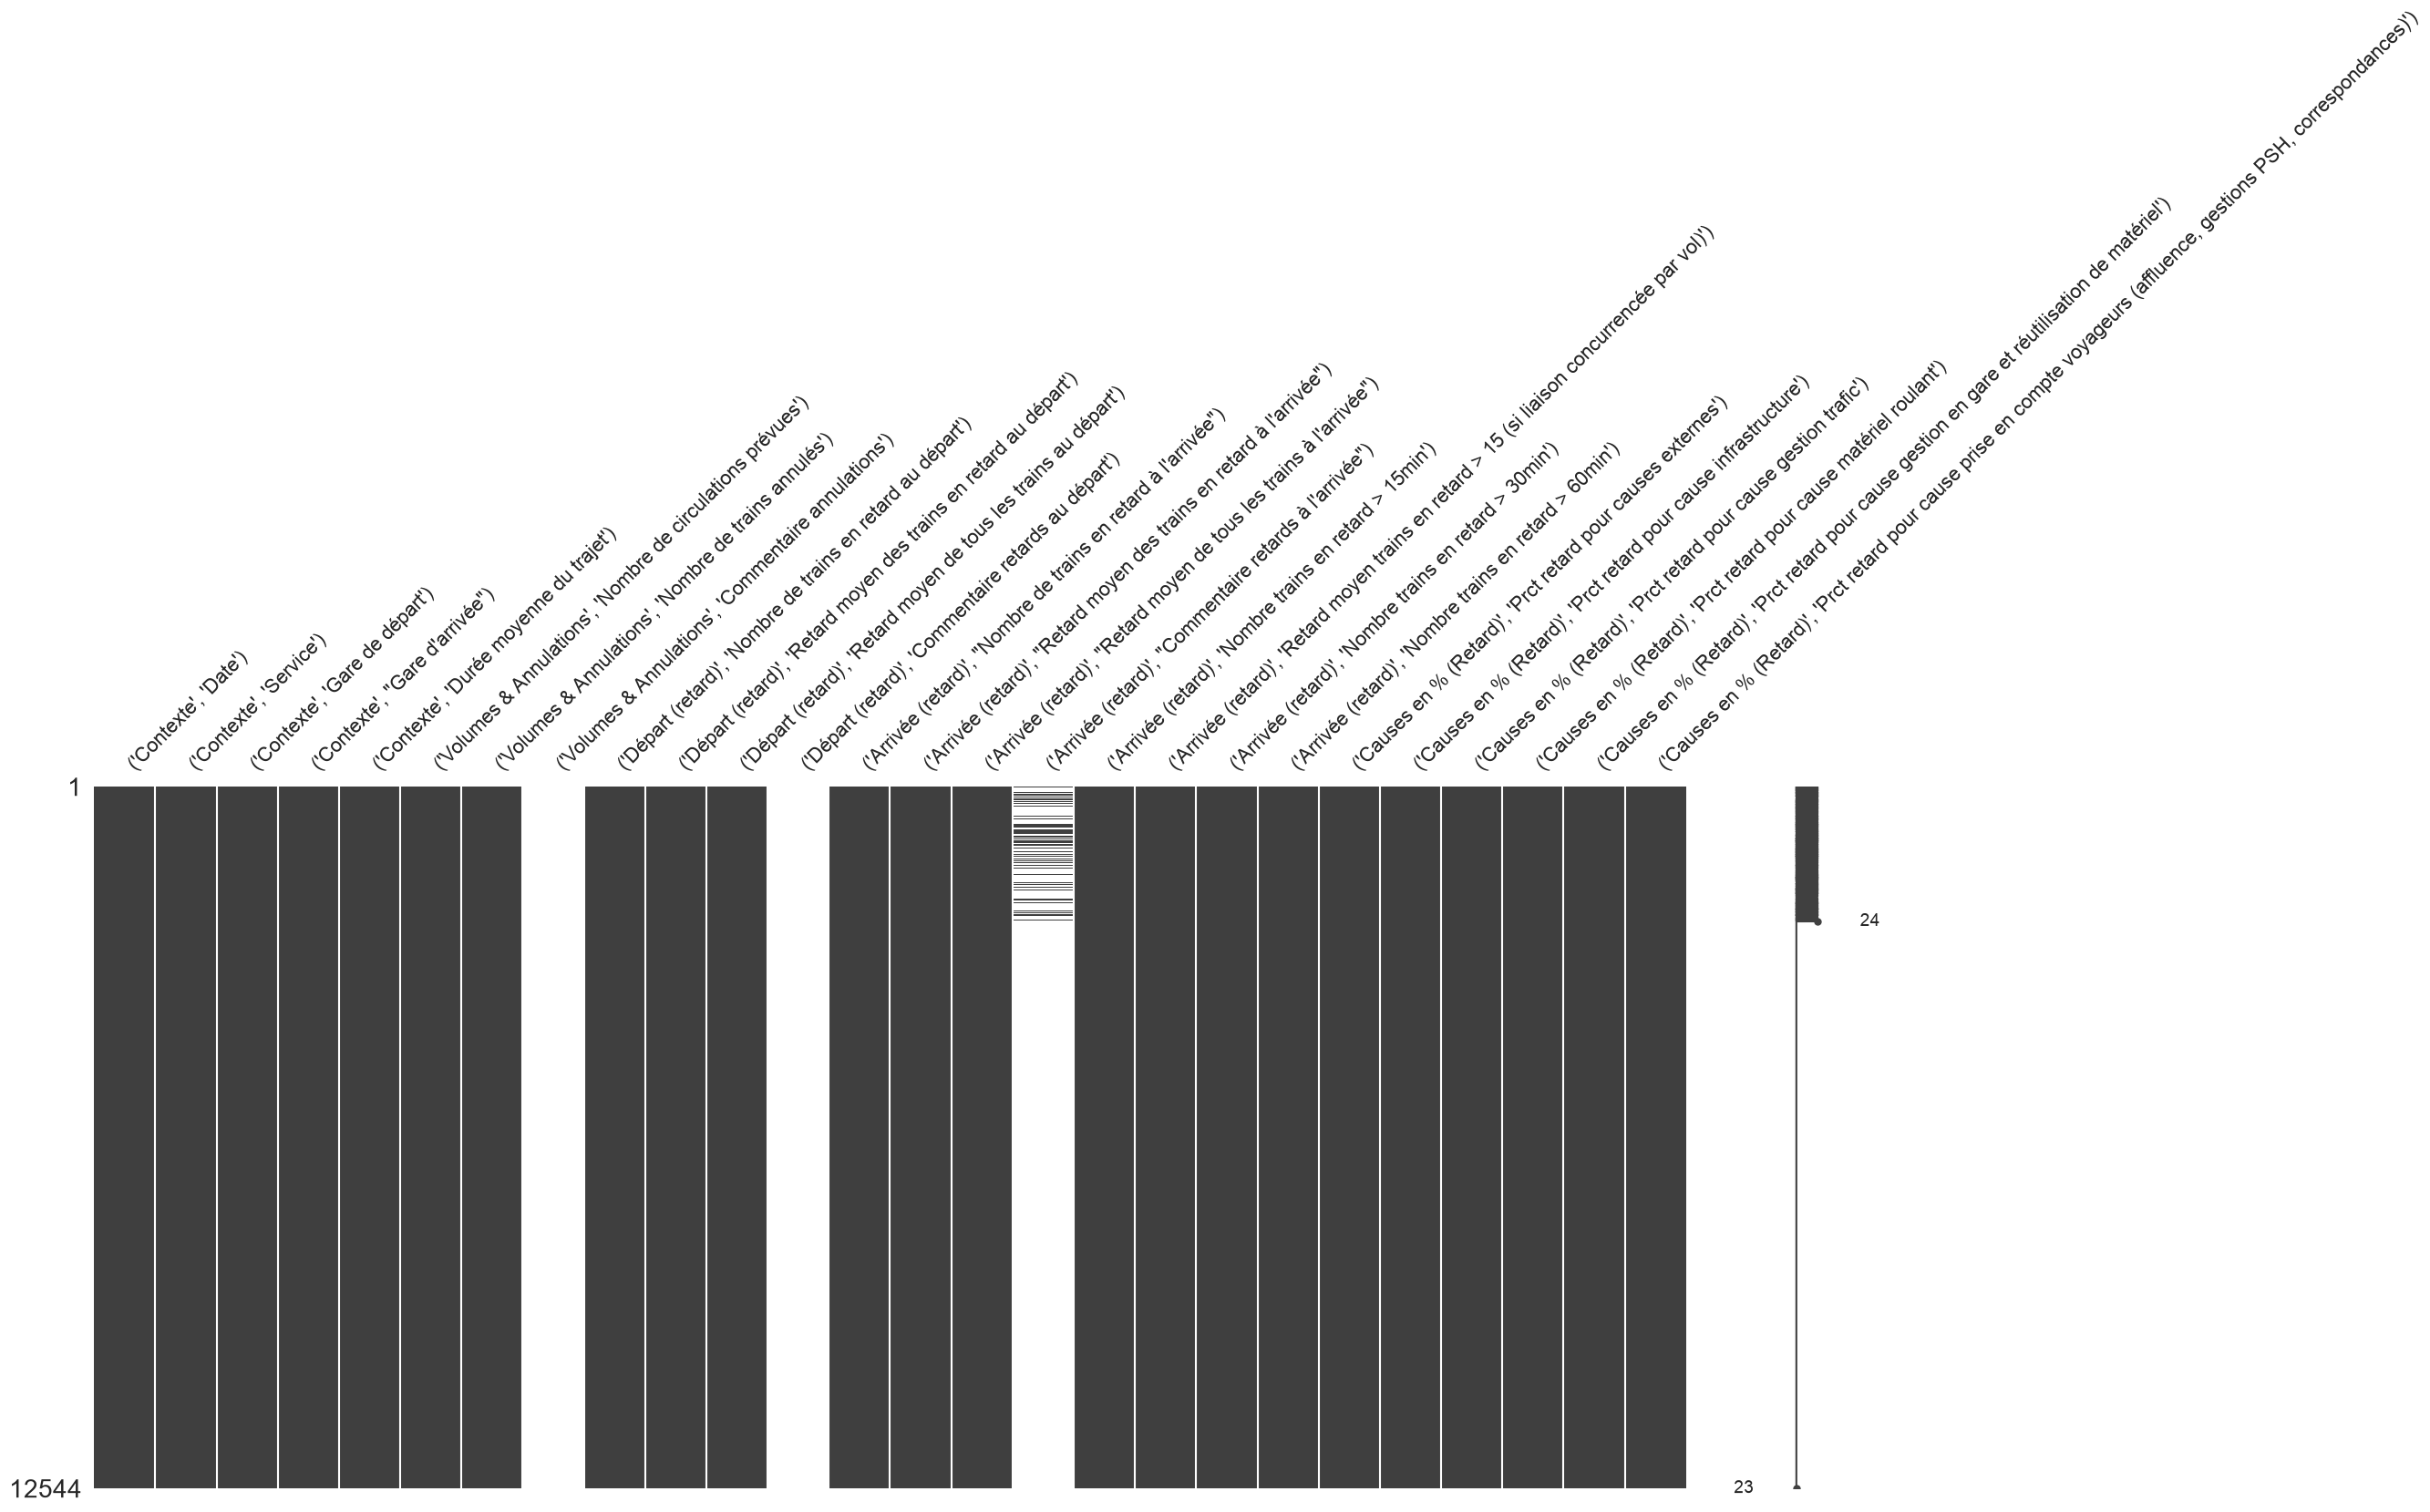

In [8]:
msno.matrix(df)
df.isna().sum()

On constate grâce aux infos globales de nos données que les colonnes :

- "Commentaire annulations" ne contient que des valeurs vides (NaN) sur l'ensemble des $12\,544$ lignes.
- "Commentaire retards au départ" ne contient que des valeurs vides (NaN) sur l'ensemble des $12\,544$ lignes.

Aussi ces deux colonnes sont donc totalement inutiles pour notre analyse, car elles ne contiennent aucune donnée exploitable.

En revanche, la colonne "Commentaire retards à l'arrivée" contient des informations pour certaines lignes (698 valeurs renseignées). Elle peut être intéressante si on souhaite analyser qualitativement les causes de perturbations.

In [9]:
df = df.drop(columns=[("Volumes & Annulations", "Commentaire annulations"), 
                      ("Départ (retard)", "Commentaire retards au départ"), 
                      ("Arrivée (retard)", "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)")])

In [10]:
df.describe(include='all')

Contexte                                          \
           Date   Service Gare de départ Gare d'arrivée   
count     12544     12544          12544          12544   
unique      102         2             59             59   
top     2025-07  National     PARIS LYON     PARIS LYON   
freq        135     11012           2560           2560   
mean        NaN       NaN            NaN            NaN   
std         NaN       NaN            NaN            NaN   
min         NaN       NaN            NaN            NaN   
25%         NaN       NaN            NaN            NaN   
50%         NaN       NaN            NaN            NaN   
75%         NaN       NaN            NaN            NaN   
max         NaN       NaN            NaN            NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count             12544.000000                   12544.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                170.628508                     272.623884   
std                  87.730733                     183.559230   
min                   0.000000                       0.000000   
25%                  99.000000                     151.000000   
50%                 163.000000                     230.000000   
75%                 223.000000                     362.000000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count              12544.000000                         12544.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.407685                            86.219866   
std                   22.089205                            88.428503   
min                    0.000000                             0.000000   
25%                    0.000000                            22.000000   
50%                    2.000000                            52.000000   
75%                    7.000000                           126.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                 12544.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     12.499854   
std                                      11.660090   
min                                       0.000000   
25%                                       6.346596   
50%                                      10.560933   
75%                                      16.101225   
max                                     316.188095   

                                                  \
       Retard moyen de tous les trains au départ   
count                               12544.000000   
unique                                       NaN   
top                                          NaN   
freq                                         NaN   
mean                                    3.175135   
std                                     5.054562   
min                                  -229.269444   
25%                                     1.226076   
50%                                     2.368000   
75%                                     4.031985   
max                                   115.047390   

                             Arrivée (retard)  \
       Nombre de trains en 

# Enrichissement des données

In [11]:

df.head(1)

Contexte                                                  \
      Date   Service    Gare de départ      Gare d'arrivée   
0  2018-01  National  BORDEAUX ST JEAN  PARIS MONTPARNASSE   

                                   Volumes & Annulations  \
  Durée moyenne du trajet Nombre de circulations prévues   
0                     141                            870   

                                                Départ (retard)  \
  Nombre de trains annulés Nombre de trains en retard au départ   
0                        5                                  289   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   

                                             \
  Retard moyen de tous les trains au départ   
0                                  3.693179   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   

                                                                               \
  Retard moyen de tous les trains à l'arrivée Commentaire retards à l'arrivée   
0                                    6.511118                             NaN   

                                                                   \
  Nombre trains en retard > 15min Nombre trains en retard > 30min   
0                             110                              44   

                                              Causes en % (Retard)  \
  Nombre trains en retard > 60min Prct retard pour causes externes   
0                               8                        36.134454   

                                                                               \
  Prct retard pour cause infrastructure Prct retard pour cause gestion trafic   
0                             31.092437                              10.92437   

                                           \
  Prct retard pour cause matériel roulant   
0                               15.966387   

                                                                       \
  Prct retard pour cause gestion en gare et réutilisation de matériel   
0                                           5.042017                    

                                                                                               
  Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)  
0                                           0.840336

In [12]:
df.describe(include='all')

Contexte                                          \
           Date   Service Gare de départ Gare d'arrivée   
count     12544     12544          12544          12544   
unique      102         2             59             59   
top     2025-07  National     PARIS LYON     PARIS LYON   
freq        135     11012           2560           2560   
mean        NaN       NaN            NaN            NaN   
std         NaN       NaN            NaN            NaN   
min         NaN       NaN            NaN            NaN   
25%         NaN       NaN            NaN            NaN   
50%         NaN       NaN            NaN            NaN   
75%         NaN       NaN            NaN            NaN   
max         NaN       NaN            NaN            NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count             12544.000000                   12544.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                170.628508                     272.623884   
std                  87.730733                     183.559230   
min                   0.000000                       0.000000   
25%                  99.000000                     151.000000   
50%                 163.000000                     230.000000   
75%                 223.000000                     362.000000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count              12544.000000                         12544.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.407685                            86.219866   
std                   22.089205                            88.428503   
min                    0.000000                             0.000000   
25%                    0.000000                            22.000000   
50%                    2.000000                            52.000000   
75%                    7.000000                           126.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                 12544.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     12.499854   
std                                      11.660090   
min                                       0.000000   
25%                                       6.346596   
50%                                      10.560933   
75%                                      16.101225   
max                                     316.188095   

                                                  \
       Retard moyen de tous les trains au départ   
count                               12544.000000   
unique                                       NaN   
top                                          NaN   
freq                                         NaN   
mean                                    3.175135   
std                                     5.054562   
min                                  -229.269444   
25%                                     1.226076   
50%                                     2.368000   
75%                                     4.031985   
max                                   115.047390   

                             Arrivée (retard)  \
       Nombre de trains en 

On ajoute une colonne donnant directement la saison (ici le mois)

In [13]:
# Création d'une nouvelle colonne "Saison" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Date"))
if not ("Contexte", "Saison") in df.columns:
    print("ajout de la colonne \"Saison\"")
    df.insert(loc=index + 1, 
              column=("Contexte", "Saison"), 
              value=df[("Contexte", "Date")].dt.month)
    df[("Contexte", "Saison")] = pd.Categorical(df[("Contexte", "Saison")], ordered=True)


ajout de la colonne "Saison"


On vérifie que la liste des gares de départ est la même que celle des gares d'arrivée (c'est le cas). Et on ajoute à chacune des gares la région française dans laquelle elle est située.

In [14]:
sorted_list_of_departures = sorted(df["Contexte"]["Gare de départ"].unique().tolist())
sorted_list_of_arrivals = sorted(df["Contexte"]["Gare d'arrivée"].unique().tolist())
if sorted(df["Contexte"]["Gare de départ"].unique().tolist()) == sorted(df["Contexte"]["Gare d'arrivée"].unique().tolist()):
    print("la liste des gares de départ est la même que celles d'arrivée")

sorted_list_of_stations = sorted_list_of_departures
print(sorted_list_of_stations)
del sorted_list_of_departures, sorted_list_of_arrivals


la liste des gares de départ est la même que celles d'arrivée
['AIX EN PROVENCE TGV', 'ANGERS SAINT LAUD', 'ANGOULEME', 'ANNECY', 'ARRAS', 'AVIGNON TGV', 'BARCELONA', 'BELLEGARDE (AIN)', 'BESANCON FRANCHE COMTE TGV', 'BORDEAUX ST JEAN', 'BREST', 'CHAMBERY CHALLES LES EAUX', 'DIJON VILLE', 'DOUAI', 'DUNKERQUE', 'FRANCFORT', 'GENEVE', 'GRENOBLE', 'ITALIE', 'LA ROCHELLE VILLE', 'LAUSANNE', 'LAVAL', 'LE CREUSOT MONTCEAU MONTCHANIN', 'LE MANS', 'LILLE', 'LYON PART DIEU', 'MACON LOCHE', 'MADRID', 'MARNE LA VALLEE', 'MARSEILLE ST CHARLES', 'METZ', 'MONTPELLIER', 'MULHOUSE VILLE', 'NANCY', 'NANTES', 'NICE VILLE', 'NIMES', 'PARIS EST', 'PARIS LYON', 'PARIS MONTPARNASSE', 'PARIS NORD', 'PARIS VAUGIRARD', 'PERPIGNAN', 'POITIERS', 'QUIMPER', 'REIMS', 'RENNES', 'SAINT ETIENNE CHATEAUCREUX', 'ST MALO', 'ST PIERRE DES CORPS', 'STRASBOURG', 'STUTTGART', 'TOULON', 'TOULOUSE MATABIAU', 'TOURCOING', 'TOURS', 'VALENCE ALIXAN TGV', 'VANNES', 'ZURICH']


In [15]:
region_mapping = {'AIX EN PROVENCE TGV': "Provence-Alpes-Côte d'Azur",
                  'ANGERS SAINT LAUD': "Pays de la Loire",
                  'ANGOULEME': "Nouvelle-Aquitaine",
                  'ANNECY': "Auvergne-Rhône-Alpes",
                  'ARRAS': "Hauts-de-France",
                  'AVIGNON TGV': "Provence-Alpes-Côte d'Azur",
                  'BARCELONA': "International (Espagne)",
                  'BELLEGARDE (AIN)': "Auvergne-Rhône-Alpes",
                  'BESANCON FRANCHE COMTE TGV': "Bourgogne-Franche-Comté",
                  'BORDEAUX ST JEAN': "Nouvelle-Aquitaine",
                  'BREST': "Bretagne",
                  'CHAMBERY CHALLES LES EAUX': "Auvergne-Rhône-Alpes",
                  'DIJON VILLE': "Bourgogne-Franche-Comté",
                  'DOUAI': "Hauts-de-France",
                  'DUNKERQUE': "Hauts-de-France",
                  'FRANCFORT': "International (Allemagne)",
                  'GENEVE': "International (Suisse)",
                  'GRENOBLE': "Auvergne-Rhône-Alpes",
                  'ITALIE': "International (Italie)",
                  'LA ROCHELLE VILLE': "Nouvelle-Aquitaine",
                  'LAUSANNE': "International (Suisse)",
                  'LAVAL': "Pays de la Loire",
                  'LE CREUSOT MONTCEAU MONTCHANIN': "Bourgogne-Franche-Comté",
                  'LE MANS': "Pays de la Loire",
                  'LILLE': "Hauts-de-France",
                  'LYON PART DIEU': "Auvergne-Rhône-Alpes",
                  'MACON LOCHE': "Bourgogne-Franche-Comté",
                  'MADRID': "International (Espagne)",
                  'MARNE LA VALLEE': "Île-de-France",
                  'MARSEILLE ST CHARLES': "Provence-Alpes-Côte d'Azur",
                  'METZ': "Grand Est",
                  'MONTPELLIER': "Occitanie",
                  'MULHOUSE VILLE': "Grand Est",
                  'NANCY': "Grand Est",
                  'NANTES': "Pays de la Loire",
                  'NICE VILLE': "Provence-Alpes-Côte d'Azur",
                  'NIMES': "Occitanie",
                  'PARIS EST': "Île-de-France",
                  'PARIS LYON': "Île-de-France",
                  'PARIS MONTPARNASSE': "Île-de-France",
                  'PARIS NORD': "Île-de-France",
                  'PARIS VAUGIRARD': "Île-de-France",
                  'PERPIGNAN': "Occitanie",
                  'POITIERS': "Nouvelle-Aquitaine",
                  'QUIMPER': "Bretagne",
                  'REIMS': "Grand Est",
                  'RENNES': "Bretagne",
                  'SAINT ETIENNE CHATEAUCREUX': "Auvergne-Rhône-Alpes",
                  'ST MALO': "Bretagne",
                  'ST PIERRE DES CORPS': "Centre-Val de Loire",
                  'STRASBOURG': "Grand Est",
                  'STUTTGART': "International (Allemagne)",
                  'TOULON': "Provence-Alpes-Côte d'Azur",
                  'TOULOUSE MATABIAU': "Occitanie",
                  'TOURCOING': "Hauts-de-France",
                  'TOURS': "Centre-Val de Loire",
                  'VALENCE ALIXAN TGV': "Auvergne-Rhône-Alpes",
                  'VANNES': "Bretagne",
                  'ZURICH': "International (Suisse)"}

# Création des 2 nouvelles colonnes "Région de départ" & "Région d'arrivée" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Gare d'arrivée"))
if not ("Contexte", "Région de départ") in df.columns:
    print("ajout de la colonne \"Région de départ\"")
    df.insert(loc=index + 1, 
              column=("Contexte", "Région de départ"), 
              value=df[("Contexte", "Gare de départ")].map(region_mapping))
    df[("Contexte", "Région de départ")] = df[("Contexte", "Région de départ")].astype('category')
if not ("Contexte", "Région d'arrivée") in df.columns:
    print("ajout de la colonne \"Région d'arrivée\"")
    df.insert(loc=index + 2, 
              column=("Contexte", "Région d'arrivée"), 
              value=df[("Contexte", "Gare d'arrivée")].map(region_mapping))
    df[("Contexte", "Région d'arrivée")] = df[("Contexte", "Région d'arrivée")].astype('category')


ajout de la colonne "Région de départ"
ajout de la colonne "Région d'arrivée"


On indique les gares d'arrivée susceptibles d'être des correspondances pour des vols d'avions.

In [16]:
# Liste des gares suceptibles d'être une correspondance pour un aéroport
station_with_airport = [
    # Hubs régionaux
    'MARSEILLE ST CHARLES',
    'NICE VILLE',
    'LYON PART DIEU',
    'STRASBOURG',
    'NANTES',
    'BORDEAUX ST JEAN',
    'TOULOUSE MATABIAU',
    'RENNES',
    'MONTPELLIER',
    'MULHOUSE VILLE',
    
    # Hub parisien
    'PARIS EST',
    'PARIS LYON',
    'PARIS MONTPARNASSE',
    'PARIS NORD',
    'PARIS VAUGIRARD',
    
    # Gares internationales majeures
    'FRANCFORT',
    'ZURICH',
    'GENEVE',
    'BARCELONA'
]

# Création d'une nouvelle colonne "Correspondance avec aéroport" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Région d'arrivée"))
if not ("Contexte", "Correspondance avec aéroport") in df.columns:
    print("ajout de la colonne \"Correspondance avec aéroport\"")
    df.insert(loc=index + 1, 
              column=("Contexte", "Correspondance avec aéroport"), 
              value=df[("Contexte", "Gare d'arrivée")].isin(station_with_airport))

ajout de la colonne "Correspondance avec aéroport"


In [17]:
df.describe(include='all')

Contexte                                                   \
           Date   Saison   Service Gare de départ Gare d'arrivée   
count     12544  12544.0     12544          12544          12544   
unique      102     12.0         2             59             59   
top     2025-07      5.0  National     PARIS LYON     PARIS LYON   
freq        135   1104.0     11012           2560           2560   
mean        NaN      NaN       NaN            NaN            NaN   
std         NaN      NaN       NaN            NaN            NaN   
min         NaN      NaN       NaN            NaN            NaN   
25%         NaN      NaN       NaN            NaN            NaN   
50%         NaN      NaN       NaN            NaN            NaN   
75%         NaN      NaN       NaN            NaN            NaN   
max         NaN      NaN       NaN            NaN            NaN   

                                                                       \
       Région de départ Région d'arrivée Correspondance avec aéroport   
count             12544            12544                        12544   
unique               15               15                            2   
top       Île-de-France    Île-de-France                         True   
freq               5455             5455                         8108   
mean                NaN              NaN                          NaN   
std                 NaN              NaN                          NaN   
min                 NaN              NaN                          NaN   
25%                 NaN              NaN                          NaN   
50%                 NaN              NaN                          NaN   
75%                 NaN              NaN                          NaN   
max                 NaN              NaN                          NaN   

                                        Volumes & Annulations  \
       Durée moyenne du trajet Nombre de circulations prévues   
count             12544.000000                   12544.000000   
unique                     NaN                            NaN   
top                        NaN                            NaN   
freq                       NaN                            NaN   
mean                170.628508                     272.623884   
std                  87.730733                     183.559230   
min                   0.000000                       0.000000   
25%                  99.000000                     151.000000   
50%                 163.000000                     230.000000   
75%                 223.000000                     362.000000   
max                 786.000000                    1100.000000   

                                                     Départ (retard)  \
       Nombre de trains annulés Nombre de trains en retard au départ   
count              12544.000000                         12544.000000   
unique                      NaN                                  NaN   
top                         NaN                                  NaN   
freq                        NaN                                  NaN   
mean                   8.407685                            86.219866   
std                   22.089205                            88.428503   
min                    0.000000                             0.000000   
25%                    0.000000                            22.000000   
50%                    2.000000                            52.000000   
75%                    7.000000                           126.000000   
max                  297.000000                           596.000000   

                                                    \
       Retard moyen des trains en retard au départ   
count                                 12544.000000   
unique                                         NaN   
top                                            NaN   
freq                                           NaN   
mean                                     12.499854   
std        

On associe aux gares d'arrivée leur correspondance aéroportuaires

In [18]:
# Dictionnaire des correspondances (Gares -> Aéroports)
station_to_airport = {
    # Hubs régionaux
    "MARSEILLE ST CHARLES": "MARSEILLE PROVENCE",
    "NICE VILLE": "NICE CÔTE D'AZUR",
    "LYON PART DIEU": "LYON SAINT-EXUPÉRY",
    "STRASBOURG": "STRASBOURG-ENTZHEIM",
    "NANTES": "NANTES ATLANTIQUE",
    "BORDEAUX ST JEAN": "BORDEAUX-MÉRIGNAC",
    "TOULOUSE MATABIAU": "TOULOUSE-BLAGNAC",
    "RENNES": "RENNES SAINT-JACQUES",
    "MONTPELLIER": "MONTPELLIER-MÉDITERRANÉE",
    "MULHOUSE VILLE": "EUROAIRPORT BASEL-MULHOUSE-FREIBURG",
    
    # Hub parisien
    "PARIS EST": "PARIS-ORLY / PARIS-CHARLES-DE-GAULLE",
    "PARIS LYON": "PARIS-ORLY / PARIS-CHARLES-DE-GAULLE",
    "PARIS MONTPARNASSE": "PARIS-ORLY / PARIS-CHARLES-DE-GAULLE",
    "PARIS NORD": "PARIS-ORLY / PARIS-CHARLES-DE-GAULLE",
    "PARIS VAUGIRARD": "PARIS-ORLY / PARIS-CHARLES-DE-GAULLE",
    
    # Gares internationales majeures
    "FRANCFORT": "AÉROPORT DE FRANCFORT",
    "ZURICH": "AÉROPORT DE ZURICH",
    "GENEVE": "AÉROPORT DE GENÈVE",
    "BARCELONA": "AÉROPORT DE BARCELONE-EL PRAT"
}

# Création d'une nouvelle colonne "Aéroport" dans le DataFrame
index = df.columns.get_loc(("Contexte", "Correspondance avec aéroport"))
if not ("Contexte", "Aéroport") in df.columns:
    print("ajout de la colonne \"Aéroport\"")
    airport_values = df.apply(lambda row: station_to_airport.get(row[("Contexte", "Gare d'arrivée")]) 
                              if row[("Contexte", "Correspondance avec aéroport")] else None, 
                              axis=1)
    df.insert(loc=index + 1, 
              column=("Contexte", "Aéroport"), 
              value=airport_values)

ajout de la colonne "Aéroport"


In [19]:
df.describe(include='all')

Contexte                                                   \
           Date   Saison   Service Gare de départ Gare d'arrivée   
count     12544  12544.0     12544          12544          12544   
unique      102     12.0         2             59             59   
top     2025-07      5.0  National     PARIS LYON     PARIS LYON   
freq        135   1104.0     11012           2560           2560   
mean        NaN      NaN       NaN            NaN            NaN   
std         NaN      NaN       NaN            NaN            NaN   
min         NaN      NaN       NaN            NaN            NaN   
25%         NaN      NaN       NaN            NaN            NaN   
50%         NaN      NaN       NaN            NaN            NaN   
75%         NaN      NaN       NaN            NaN            NaN   
max         NaN      NaN       NaN            NaN            NaN   

                                                                       \
       Région de départ Région d'arrivée Correspondance avec aéroport   
count             12544            12544                        12544   
unique               15               15                            2   
top       Île-de-France    Île-de-France                         True   
freq               5455             5455                         8108   
mean                NaN              NaN                          NaN   
std                 NaN              NaN                          NaN   
min                 NaN              NaN                          NaN   
25%                 NaN              NaN                          NaN   
50%                 NaN              NaN                          NaN   
75%                 NaN              NaN                          NaN   
max                 NaN              NaN                          NaN   

                                                                      \
                                    Aéroport Durée moyenne du trajet   
count                                   8108            12544.000000   
unique                                    15                     NaN   
top     PARIS-ORLY / PARIS-CHARLES-DE-GAULLE                     NaN   
freq                                    5251                     NaN   
mean                                     NaN              170.628508   
std                                      NaN               87.730733   
min                                      NaN                0.000000   
25%                                      NaN               99.000000   
50%                                      NaN              163.000000   
75%                                      NaN              223.000000   
max                                      NaN              786.000000   

                Volumes & Annulations                           \
       Nombre de circulations prévues Nombre de trains annulés   
count                    12544.000000             12544.000000   
unique                            NaN                      NaN   
top                               NaN                      NaN   
freq                              NaN                      NaN   
mean                       272.623884                 8.407685   
std                        183.559230                22.089205   
min                          0.000000                 0.000000   
25%                        151.000000                 0.000000   
50%                        230.000000                 2.000000   
75%                        362.000000                 7.000000   
max                       1100.000000               297.000000   

                            Départ (retard)  \
       Nombre de trains en retard au départ   
count                          12544.000000   
unique                                  NaN   
top                                     NaN   
freq                                    NaN   
mean                              86.219866   
std                               88.428503   


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12544 entries, 0 to 12543
Data columns (total 28 columns):
 #   Column                                                                                                               Non-Null Count  Dtype    
---  ------                                                                                                               --------------  -----    
 0   (Contexte, Date)                                                                                                     12544 non-null  period[M]
 1   (Contexte, Saison)                                                                                                   12544 non-null  category 
 2   (Contexte, Service)                                                                                                  12544 non-null  category 
 3   (Contexte, Gare de départ)                                                                                           12544 non-null  category 
 4   (Contexte

# Saisonnalité du retard

In [21]:
df = pd.read_csv("../data/regularite-mensuelle-tgv-aqst.csv", sep=";")
data_preprocessing.preprocessing(df)
data_preprocessing.enrichment(df)
df.head()

ajout de la colonne "Saison"
ajout de la colonne "Région de départ"
ajout de la colonne "Région d'arrivée"
ajout de la colonne "Correspondance avec aéroport"
Ajout de la colonne "Aéroport"


Contexte                                                           \
      Date Saison   Service      Gare de départ      Gare d'arrivée   
0  2018-01      1  National    BORDEAUX ST JEAN  PARIS MONTPARNASSE   
1  2018-01      1  National             LE MANS  PARIS MONTPARNASSE   
2  2018-01      1  National  PARIS MONTPARNASSE   LA ROCHELLE VILLE   
3  2018-01      1  National  PARIS MONTPARNASSE              NANTES   
4  2018-01      1  National            POITIERS  PARIS MONTPARNASSE   

                                                                        \
     Région de départ    Région d'arrivée Correspondance avec aéroport   
0  Nouvelle-Aquitaine       Île-de-France                         True   
1    Pays de la Loire       Île-de-France                         True   
2       Île-de-France  Nouvelle-Aquitaine                        False   
3       Île-de-France    Pays de la Loire                         True   
4  Nouvelle-Aquitaine       Île-de-France                         True   

                                                                 \
                               Aéroport Durée moyenne du trajet   
0  PARIS-ORLY / PARIS-CHARLES-DE-GAULLE                     141   
1  PARIS-ORLY / PARIS-CHARLES-DE-GAULLE                      56   
2                                   NaN                     166   
3                     NANTES ATLANTIQUE                     124   
4  PARIS-ORLY / PARIS-CHARLES-DE-GAULLE                      94   

           Volumes & Annulations                           \
  Nombre de circulations prévues Nombre de trains annulés   
0                            870                        5   
1                            406                        1   
2                            226                        0   
3                            508                        3   
4                            472                        4   

                       Départ (retard)  \
  Nombre de trains en retard au départ   
0                                  289   
1                                  213   
2                                   21   
3                                   71   
4                                  224   

                                               \
  Retard moyen des trains en retard au départ   
0                                   11.247809   
1                                    8.479969   
2                                    6.239683   
3                                    7.235211   
4                                    6.784673   

                                             \
  Retard moyen de tous les trains au départ   
0                                  3.693179   
1                                  4.567119   
2                                  0.286283   
3                                  0.734290   
4                                  3.229701   

                        Arrivée (retard)  \
  Nombre de trains en retard à l'arrivée   
0                                    147   
1                                    105   
2                                     19   
3                                     58   
4                                     89   

                                                 \
  Retard moyen des trains en retard à l'arrivée   
0                                     28.436735   
1                                     18.049048   
2                                     24.736842   
3                                     33.726437   
4                                     14.592697   

                                               \
  Retard moyen de tous les trains à l'arrivée   
0                                    6.511118   
1                                    5.363539   
2                                    2.938053   
3                                    5.292211   
4                                    4.882372   

                                                      \
                     Commentaire retards à l'arrivé

In [22]:
df.describe(include='all')

Contexte                                                   \
           Date   Saison   Service Gare de départ Gare d'arrivée   
count     12544  12544.0     12544          12544          12544   
unique      102     12.0         2             59             59   
top     2025-07      5.0  National     PARIS LYON     PARIS LYON   
freq        135   1104.0     11012           2560           2560   
mean        NaN      NaN       NaN            NaN            NaN   
std         NaN      NaN       NaN            NaN            NaN   
min         NaN      NaN       NaN            NaN            NaN   
25%         NaN      NaN       NaN            NaN            NaN   
50%         NaN      NaN       NaN            NaN            NaN   
75%         NaN      NaN       NaN            NaN            NaN   
max         NaN      NaN       NaN            NaN            NaN   

                                                                       \
       Région de départ Région d'arrivée Correspondance avec aéroport   
count             12544            12544                        12544   
unique               15               15                            2   
top       Île-de-France    Île-de-France                         True   
freq               5455             5455                         8108   
mean                NaN              NaN                          NaN   
std                 NaN              NaN                          NaN   
min                 NaN              NaN                          NaN   
25%                 NaN              NaN                          NaN   
50%                 NaN              NaN                          NaN   
75%                 NaN              NaN                          NaN   
max                 NaN              NaN                          NaN   

                                                                      \
                                    Aéroport Durée moyenne du trajet   
count                                   8108            12544.000000   
unique                                    15                     NaN   
top     PARIS-ORLY / PARIS-CHARLES-DE-GAULLE                     NaN   
freq                                    5251                     NaN   
mean                                     NaN              170.628508   
std                                      NaN               87.730733   
min                                      NaN                0.000000   
25%                                      NaN               99.000000   
50%                                      NaN              163.000000   
75%                                      NaN              223.000000   
max                                      NaN              786.000000   

                Volumes & Annulations                           \
       Nombre de circulations prévues Nombre de trains annulés   
count                    12544.000000             12544.000000   
unique                            NaN                      NaN   
top                               NaN                      NaN   
freq                              NaN                      NaN   
mean                       272.623884                 8.407685   
std                        183.559230                22.089205   
min                          0.000000                 0.000000   
25%                        151.000000                 0.000000   
50%                        230.000000                 2.000000   
75%                        362.000000                 7.000000   
max                       1100.000000               297.000000   

                            Départ (retard)  \
       Nombre de trains en retard au départ   
count                          12544.000000   
unique                                  NaN   
top                                     NaN   
freq                                    NaN   
mean                              86.219866   
std                               88.428503   


À partir de maintenant, on se concentre sur liaisons (lignes de nos données) pour lesquels les "gare d'arrivée" sont potentiellement des "correspondance avec aéroport"

In [23]:
# Isole le sous-ensemble des liaisons permettant une correspondance potentielle avec un aéroport
df_airport = df[df[("Contexte","Correspondance avec aéroport")] == True]
df_airport.describe(include='all')

Contexte                                                  \
           Date  Saison   Service Gare de départ Gare d'arrivée   
count      8108  8108.0      8108           8108           8108   
unique      102    12.0         2             58             19   
top     2025-07     5.0  National     PARIS LYON     PARIS LYON   
freq         88   713.0      6935            818           2560   
mean        NaN     NaN       NaN            NaN            NaN   
std         NaN     NaN       NaN            NaN            NaN   
min         NaN     NaN       NaN            NaN            NaN   
25%         NaN     NaN       NaN            NaN            NaN   
50%         NaN     NaN       NaN            NaN            NaN   
75%         NaN     NaN       NaN            NaN            NaN   
max         NaN     NaN       NaN            NaN            NaN   

                                                                       \
       Région de départ Région d'arrivée Correspondance avec aéroport   
count              8108             8108                         8108   
unique               15               11                            1   
top       Île-de-France    Île-de-France                         True   
freq               1673             5251                         8108   
mean                NaN              NaN                          NaN   
std                 NaN              NaN                          NaN   
min                 NaN              NaN                          NaN   
25%                 NaN              NaN                          NaN   
50%                 NaN              NaN                          NaN   
75%                 NaN              NaN                          NaN   
max                 NaN              NaN                          NaN   

                                                                      \
                                    Aéroport Durée moyenne du trajet   
count                                   8108             8108.000000   
unique                                    15                     NaN   
top     PARIS-ORLY / PARIS-CHARLES-DE-GAULLE                     NaN   
freq                                    5251                     NaN   
mean                                     NaN              176.984953   
std                                      NaN               87.996325   
min                                      NaN                0.000000   
25%                                      NaN              108.000000   
50%                                      NaN              168.000000   
75%                                      NaN              228.000000   
max                                      NaN              786.000000   

                Volumes & Annulations                           \
       Nombre de circulations prévues Nombre de trains annulés   
count                     8108.000000              8108.000000   
unique                            NaN                      NaN   
top                               NaN                      NaN   
freq                              NaN                      NaN   
mean                       286.927232                 8.697089   
std                        201.765087                23.199974   
min                          0.000000                 0.000000   
25%                        152.000000                 0.000000   
50%                        233.000000                 2.000000   
75%                        399.250000                 7.000000   
max                       1100.000000               297.000000   

                            Départ (retard)  \
       Nombre de trains en retard au départ   
count                           8108.000000   
unique                                  NaN   
top                                     NaN   
freq                                    NaN   
mean                             103.691539   
std                               95.009548   
min          

In [24]:
df_airport_seasonality = data_preprocessing.airport_seasonality(df)
df_airport_seasonality.head(1)

,"(Contexte, Saison)","(Contexte, Gare de départ)","(Contexte, Gare d'arrivée)","(Contexte, Aéroport)",Volume total des circulations prévues,Volume total de trains annulés,Volume total de trains en retard à l'arrivée,Retard moyen des trains à l'arrivée,Volume total de trains en retard > 15 min,Volume total de trains en retard > 30 min,Volume total de trains en retard > 60 min
0,1,AIX EN PROVENCE TGV,PARIS LYON,PARIS-ORLY / PARIS-CHARLES-DE-GAULLE,3637.0,52.0,393.0,45.275147,382.0,182.0,94.0


In [25]:
df_airport_seasonality.describe(include='all')

,"(Contexte, Saison)","(Contexte, Gare de départ)","(Contexte, Gare d'arrivée)","(Contexte, Aéroport)",Volume total des circulations prévues,Volume total de trains annulés,Volume total de trains en retard à l'arrivée,Retard moyen des trains à l'arrivée,Volume total de trains en retard > 15 min,Volume total de trains en retard > 30 min,Volume total de trains en retard > 60 min
count,1032.0,1032,1032,1032,1032.000000,1032.000000,1032.000000,1032.000000,1032.000000,1032.000000,1032.000000
unique,12.0,58,19,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,1.0,PARIS LYON,PARIS LYON,PARIS-ORLY / PARIS-CHARLES-DE-GAULLE,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,86.0,96,300,648,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,2254.269380,68.329457,325.531977,37.268647,236.040698,111.278101,46.391473
std,NaN,NaN,NaN,NaN,1687.699268,86.621981,252.219380,11.399002,175.451332,87.234253,37.743941
min,NaN,NaN,NaN,NaN,7.000000,0.000000,0.000000,0.000000,0.000000,-4.000000,0.000000
25%,NaN,NaN,NaN,NaN,1138.000000,15.000000,147.750000,31.127432,97.500000,46.000000,18.000000
50%,NaN,NaN,NaN,NaN,1844.000000,38.000000,267.500000,37.040231,213.000000,94.500000,39.000000
75%,NaN,NaN,NaN,NaN,3284.250000,88.250000,471.750000,44.279112,333.000000,154.250000,66.000000


In [26]:
for colonne in df_airport.columns:
    print(colonne)

('Contexte', 'Date')
('Contexte', 'Saison')
('Contexte', 'Service')
('Contexte', 'Gare de départ')
('Contexte', "Gare d'arrivée")
('Contexte', 'Région de départ')
('Contexte', "Région d'arrivée")
('Contexte', 'Correspondance avec aéroport')
('Contexte', 'Aéroport')
('Contexte', 'Durée moyenne du trajet')
('Volumes & Annulations', 'Nombre de circulations prévues')
('Volumes & Annulations', 'Nombre de trains annulés')
('Départ (retard)', 'Nombre de trains en retard au départ')
('Départ (retard)', 'Retard moyen des trains en retard au départ')
('Départ (retard)', 'Retard moyen de tous les trains au départ')
('Arrivée (retard)', "Nombre de trains en retard à l'arrivée")
('Arrivée (retard)', "Retard moyen des trains en retard à l'arrivée")
('Arrivée (retard)', "Retard moyen de tous les trains à l'arrivée")
('Arrivée (retard)', "Commentaire retards à l'arrivée")
('Arrivée (retard)', 'Nombre trains en retard > 15min')
('Arrivée (retard)', 'Nombre trains en retard > 30min')
('Arrivée (retard)'

# Fusionner Paris Vaugirard et Montparnasse

In [27]:
# Fusion des lignes Paris Vaugirard avec Paris Montparnasse en "Paris Montparnasse"
# Calcul refait sur toutes les lignes par simplicité, résultats inchangés pour les lignes non concernées (multiplier les moyennes par le cardinal et rediviser par le  même cardinal)

data = df.copy()

data.columns = data.columns.droplevel(0)

# supprimer les colonnes inutiles pour la suite.
a_supprimer = [
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
    "Commentaire retards à l'arrivée",
]
data = data.drop(columns=a_supprimer)

# Remplacer Paris Vaugirard par Paris Montparnasse (gares fusionnées)
for colonne in ["Gare de départ", "Gare d'arrivée"]:
    data[colonne] = data[colonne].astype(str).replace("PARIS VAUGIRARD", "PARIS MONTPARNASSE")

# Nombre de trains réellement partis (sert de poids)
data["Nombre de trains réalisés"] = data["Nombre de circulations prévues"] - data["Nombre de trains annulés"] # TODO rajouter, à supprimer à la fin

# fixer les poids pour le calcul des nouvelles moyennes pondérées : Montparnasse + Vaugirard = Montparnasse fusionnées

# poids = {colonne  recalculée : colonne des coefficients de pondération de la colonne à recalculer}
poids = {
    "Durée moyenne du trajet":                        "Nombre de trains réalisés",
    "Retard moyen des trains en retard au départ":    "Nombre de trains en retard au départ",
    "Retard moyen de tous les trains au départ":      "Nombre de trains réalisés",
    "Retard moyen des trains en retard à l'arrivée":  "Nombre de trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée":    "Nombre de trains réalisés",
}

# Calcul de la  valeur mensuel totale des retards par ligne  :
for moyenne, nombre in poids.items():
    data[moyenne] = data[moyenne] * data[nombre]

# Regrouper les lignes identiques Montparnasse fusionnées (même mois, même départ, même arrivée)
cles = ["Date", "Gare de départ", "Gare d'arrivée"]

colonnes_a_additionner = [
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains réalisés",              # TODO rajouter, à supprimer à la fin
    "Nombre de trains en retard au départ",
    "Nombre de trains en retard à l'arrivée",
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
]

regles = {} #sum ou prendre le first dans le agg du groupby
for colonne in data.columns:

    if colonne in colonnes_a_additionner or colonne in poids:
        regles[colonne] = "sum"      # on additionne les valeurs des deux lignes dont cles = ["Date", "Gare de départ", "Gare d'arrivée"] sont identiques
    else:
        regles[colonne] = "first"    # on garde la valeur de la première ligne (Service, Région…) si non concerné => ne change rien, si Vaugirard ou Montparnasse, ces valeurs sont identiques, ou n'ont pas d'impact pour la suite.

data = data.groupby(cles, as_index=False).agg(regles) # groupby les lignes ayant même colonnes clés, et sum ou first dans les colonnes.

# Total -> moyenne
for moyenne, nombre in poids.items():
    data[moyenne] = data[moyenne] / data[nombre] # on redivise la somme totale par les nombre de trajet (Montparnasse + Vaugirard) pour avoir la moyenne pondérée

In [28]:
data=data.drop(columns="Nombre de trains réalisés")
data.describe()

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
count,12420.000000,12430.000000,12430.000000,12430.000000,12301.000000,12420.000000,12430.000000,12241.000000,12420.000000,12430.000000,12430.000000,12430.000000
mean,171.089862,275.124216,8.484795,87.010619,12.590497,3.169864,38.594047,35.994568,6.193601,27.829445,13.145455,5.419871
std,87.932184,183.886029,22.206567,88.697924,11.612285,5.056748,31.950435,15.025592,6.938515,23.417150,12.751999,6.283649
min,-0.000000,0.000000,0.000000,0.000000,0.100000,-229.269444,0.000000,-40.109259,-472.638889,0.000000,-44.000000,0.000000
25%,99.000000,154.000000,0.000000,22.000000,6.470588,1.229683,16.000000,26.343452,3.464411,11.000000,4.000000,1.000000
50%,164.000000,232.000000,2.000000,53.000000,10.659375,2.367572,30.000000,33.990113,5.453841,22.000000,10.000000,3.000000
75%,224.000000,367.000000,7.000000,127.000000,16.151190,4.029608,53.000000,42.938333,8.244466,38.000000,18.000000,7.000000
max,786.000000,1100.000000,297.000000,596.000000,316.188095,115.047390,376.000000,299.600000,92.000000,312.000000,202.000000,77.000000


# récupération des retards de janvier à mars 2025

In [29]:
data[(data["Date"] >= "2025-01") & (data["Date"] <= "2025-03") & (data["Nombre trains en retard > 30min"] <= 0)].describe()

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
count,347.000000,347.000000,347.000000,347.000000,347.000000,347.000000,347.000000,344.000000,347.000000,347.000000,347.000000,347.00000
mean,175.025937,297.014409,2.478386,72.227666,14.905367,2.769302,38.452450,38.487560,5.972580,28.051873,-0.613833,13.56196
std,93.287900,191.500018,6.641651,77.006550,9.539629,2.725584,28.341332,14.994960,3.213311,19.563079,3.109864,9.91079
min,46.000000,22.000000,0.000000,1.000000,1.539583,-0.149421,0.000000,12.797297,-1.155914,0.000000,-44.000000,0.00000
25%,101.500000,174.000000,0.000000,17.000000,8.510161,1.107004,18.000000,27.777888,3.580509,13.000000,0.000000,6.00000
50%,168.000000,244.000000,0.000000,37.000000,12.278632,2.205534,32.000000,36.884558,5.422400,23.000000,0.000000,12.00000
75%,227.500000,412.500000,2.000000,104.500000,19.545473,3.421091,53.000000,45.432719,7.639837,39.500000,0.000000,19.00000
max,564.000000,1029.000000,53.000000,341.000000,75.950000,26.634946,180.000000,104.000000,19.114881,132.000000,0.000000,69.00000


**Constat** : on remarque que 221 lignes n'ont pas de "retard > 30 min" ou négatif (impossible) entre janvier et mars 2025 , ce qui pénalise la suite de notre étude de données.

**Etude** : regarder une fenêtre plus large [octobre-24,juin-25] :

In [30]:
dezoom = data[(data["Date"] >= "2024-10") & (data["Date"] <= "2025-06")]
dezoom.groupby("Date")[["Nombre trains en retard > 15min", "Nombre trains en retard > 30min", "Nombre trains en retard > 60min"]].sum()


,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
Date,,,
2024-10,2986,1306,410
2024-11,3982,1962,682
2024-12,3655,1631,674
2025-01,3873,-81,1882
2025-02,3106,-74,1462
2025-03,3156,-16,1586
2025-04,2865,1280,434
2025-05,2942,1496,540
2025-06,4784,2374,815


In [31]:
compare = dezoom.groupby("Date")[["Nombre trains en retard > 15min", "Nombre trains en retard > 30min", "Nombre trains en retard > 60min"]].sum()
compare["> 30 / > 15"] = compare["Nombre trains en retard > 30min"] / compare["Nombre trains en retard > 15min"]
compare["> 60 / > 15"] = compare["Nombre trains en retard > 60min"] / compare["Nombre trains en retard > 15min"]
compare.round(2)

,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min,> 30 / > 15,> 60 / > 15
Date,,,,,
2024-10,2986,1306,410,0.44,0.14
2024-11,3982,1962,682,0.49,0.17
2024-12,3655,1631,674,0.45,0.18
2025-01,3873,-81,1882,-0.02,0.49
2025-02,3106,-74,1462,-0.02,0.47
2025-03,3156,-16,1586,-0.01,0.50
2025-04,2865,1280,434,0.45,0.15
2025-05,2942,1496,540,0.51,0.18
2025-06,4784,2374,815,0.50,0.17


**Choix** : Au vu des coefficients [>30/>15, >60/>15] Il est fort probable qu'il y ait une erreur de saisie.   

Dans les lignes ou le retard >30min est < = 0 , transférer la valeur de la colonne >60, ce qui décale le manque de données.

In [32]:
# trouver les R30 <= 0, les rempalcer par R60 et R60 = NaN pour le futur KNN

R30 = "Nombre trains en retard > 30min"
R60 = "Nombre trains en retard > 60min"
mois_faux = ["2025-01", "2025-02", "2025-03"]

for i in data.index:                                # parcours le df
    if str(data.loc[i, "Date"]) in mois_faux:       # trouve les date 2025-01 -02 -03
        if data.loc[i, R30] <= 0:
            data.loc[i, R30] = data.loc[i, R60]     # remplace R30 par R60
            data.loc[i, R60] = np.nan   

**Problématique** : retrouver maintenant les données manquantes >60 par la méthode des **knn** par rapport aux deux autres colonnes catégoriel "retard > 15" et "retard > 30".

**KNN** :

les colonnes de référence ~ toutes les colonnes qui concernent les retards à l'arrivée :  

-  Retard moyen de tous les trains au départ
-  Nombre de trains en retard à l'arrivée
-  Retard moyen des trains en retard à l'arrivée
-  Nombre trains en retard > 15min
-  Nombre trains en retard > 30min

**Colonne cible : Nombre trains en retard > 60min**

In [33]:
# KNN pour compléter les NaN de R60 = "Nombre trains en retard > 60min"

colonnesKNN = [
    "Nombre trains en retard > 15min",
    "Nombre trains en retard > 30min",
    "Nombre de trains en retard à l'arrivée",
    "Retard moyen des trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée",
    R60
]

imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(data[colonnesKNN])

data[R60] = X_imputed[:,-1].round()

In [34]:
data[(data["Date"] >= "2025-01") & (data["Date"] <= "2025-03")].describe()

,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
count,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,360.000000,363.000000,363.000000,363.000000,363.000000
mean,173.752066,299.198347,2.724518,71.958678,14.894638,2.751228,38.393939,38.705243,5.947247,27.920110,13.079890,5.793388
std,92.732993,191.807567,7.036301,76.127807,9.454075,2.691263,28.165683,15.130430,3.204228,19.496754,9.967445,5.419808
min,46.000000,22.000000,0.000000,1.000000,1.539583,-0.149421,0.000000,12.797297,-1.155914,0.000000,0.000000,0.000000
25%,100.500000,175.000000,0.000000,17.000000,8.510161,1.111828,18.000000,27.992663,3.564447,13.000000,5.000000,2.000000
50%,163.000000,244.000000,0.000000,37.000000,12.381965,2.189038,32.000000,36.962210,5.396715,23.000000,11.000000,4.000000
75%,227.500000,417.000000,2.000000,104.500000,19.545473,3.413530,53.000000,45.718988,7.639837,39.000000,19.000000,8.000000
max,564.000000,1029.000000,53.000000,341.000000,75.950000,26.634946,180.000000,104.000000,19.114881,132.000000,69.000000,50.000000


# Prévision 2027 - régression par saison

**problématique** : 2018-2026 ne suffit par faire une regression mensuelle (9 mois de janvier sont insuffisants pour estimer le 10 e de 2027) 

**choix des données** : regroupement par saison pour augmenter le nombre de points nécessaire à la regression linéaire

In [35]:
saisons = {
    1:     [1, 2, 3], # Hiver
    2:     [4, 5, 6],   # Printemps
    3:     [7, 8, 9],   # Eté
    4:     [10, 11, 12], # Autonome
}

In [36]:
data.head(1)

,Date,Saison,Service,Gare de départ,Gare d'arrivée,Région de départ,Région d'arrivée,Correspondance avec aéroport,Aéroport,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
0,2018-01,1,National,AIX EN PROVENCE TGV,PARIS LYON,Provence-Alpes-Côte d'Azur,Île-de-France,True,PARIS-ORLY / PARIS-CHARLES-DE-GAULLE,188.0,402,0,117,6.625641,2.005431,37,35.974324,4.417206,37,19,7.0


In [37]:
data["Mois"] = data["Date"].dt.month

In [38]:
# Renseigner Saison en fonction du mois

for num, month in saisons.items():
    data.loc[data["Mois"].isin(month), 'Saison'] = num 


In [39]:
# extraire l'année de la colonne "Date" 

data["Année"]=data["Date"].dt.year

premieres = ["Date", "Année", "Saison", "Mois"]
autres = [c for c in data.columns if c not in premieres]
data = data[premieres + autres]

In [40]:
data.head(1)

,Date,Année,Saison,Mois,Service,Gare de départ,Gare d'arrivée,Région de départ,Région d'arrivée,Correspondance avec aéroport,Aéroport,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
0,2018-01,2018,1,1,National,AIX EN PROVENCE TGV,PARIS LYON,Provence-Alpes-Côte d'Azur,Île-de-France,True,PARIS-ORLY / PARIS-CHARLES-DE-GAULLE,188.0,402,0,117,6.625641,2.005431,37,35.974324,4.417206,37,19,7.0


In [41]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 12430 entries, 0 to 12429
Data columns (total 23 columns):
 #   Column                                         Non-Null Count  Dtype    
---  ------                                         --------------  -----    
 0   Date                                           12430 non-null  period[M]
 1   Année                                          12430 non-null  int64    
 2   Saison                                         12430 non-null  category 
 3   Mois                                           12430 non-null  int64    
 4   Service                                        12430 non-null  category 
 5   Gare de départ                                 12430 non-null  str      
 6   Gare d'arrivée                                 12430 non-null  str      
 7   Région de départ                               12430 non-null  category 
 8   Région d'arrivée                               12430 non-null  category 
 9   Correspondance avec aéroport           

In [42]:
colonne = "Retard moyen des trains en retard à l'arrivée"

# Liste des liaisons (couples départ / arrivée), sans doublon
liaisons = data[["Gare de départ", "Gare d'arrivée"]].drop_duplicates()

resultats = []    # une ligne de résultat par liaison et par saison

for depart, arrivee in zip(liaisons["Gare de départ"], liaisons["Gare d'arrivée"]):
    trajet = data[(data["Gare de départ"] == depart) & (data["Gare d'arrivée"] == arrivee)]

    for saison in [1, 2, 3, 4]:
        donnees = trajet[trajet["Saison"] == saison].dropna(subset=[colonne])

        # Pas assez de points (ou une seule année) : régression impossible
        if len(donnees) < 3 or donnees["Année"].nunique() < 2:
            continue

        reg = linregress(donnees["Année"], donnees[colonne])

        resultats.append({
            "Gare de départ": depart,
            "Gare d'arrivée": arrivee,
            "Saison": saison,
            "Nombre de points": len(donnees),
            "Pente (min/an)": reg.slope,
            "p-value": reg.pvalue,
            "R²": reg.rvalue ** 2,
            "Prévision 2027 (min)": reg.intercept + reg.slope * 2027,
        })

resultats = pd.DataFrame(resultats)

In [43]:
resultats.describe()

,Saison,Nombre de points,Pente (min/an),p-value,R²,Prévision 2027 (min)
count,492.000000,492.000000,492.000000,492.000000,4.920000e+02,492.000000
mean,2.500000,24.861789,0.915648,0.301704,1.292733e-01,40.662160
std,1.119172,2.794598,2.156418,0.316296,1.394583e-01,17.859890
min,1.000000,4.000000,-23.415385,0.000005,5.883582e-08,-128.683333
25%,1.750000,24.000000,0.281015,0.026650,1.570232e-02,33.347488
50%,2.500000,24.000000,1.024399,0.175730,7.983752e-02,40.897915
75%,3.250000,27.000000,1.744961,0.559061,1.978412e-01,48.251312
max,4.000000,27.000000,13.339583,0.999042,8.051827e-01,173.889583


# Conclusion regression linéaire

Les p-value sont globalement supérieures au seuil de 0.05, du fait du faible nombre de points disponibles malgré la regression faite par saison. Chaque prédiction de trajet est donc peut pertinente.

Cependant, on remarque qu'une tendance sur l'ensemble du réseau se dégage (la p-value n'est pas distribuée aléatoirement entre 0 et 1. sans tendance, la p-value serait répartie plus uniformément sur [0,1]) : les retards ont tendance à augmenter au cours des années.

Après de multiple essais pour construire un indice de fiabilité, il est difficile de proposer un indice fiable.

**Choix pour la seconde reflexion** : sauf quelques cas particuliers, la regression linéaire permet de conclure que les retards augmentent de +0 à +2min par an sur l'ensemble du réseau de manière similaire. Ainsi, se baser sur les retards catégorisés par la SNCF [15,30 min], [30,60min], >60 min des 24 derniers mois permet d'obtenir un indicateur plus simple et plus fiable de chaque trajet.

En rajoutant des pénalités croissantes en fonction du retard, **l'indacteur retenu** est :

$$Fiabilité =\frac{P - 0.33*N_{15/30} - 0.66*N_{30/60} - N_{>60} - A}{P}$$

$P$         : trajets prévus (réalisés + annulés)  
$A$         : trajets annulés  
$N_{15/30}$ : nombre de trains ayant entre 15 et 30 minutes de retard  
$N_{30/60}$ : nombre de trains ayant entre 30 et 60 minutes de retard  
$N_{>60}$   : nombre de trains ayant plus de 60 minutes de retard  



In [44]:
data.head(1)

,Date,Année,Saison,Mois,Service,Gare de départ,Gare d'arrivée,Région de départ,Région d'arrivée,Correspondance avec aéroport,Aéroport,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Nombre trains en retard > 15min,Nombre trains en retard > 30min,Nombre trains en retard > 60min
0,2018-01,2018,1,1,National,AIX EN PROVENCE TGV,PARIS LYON,Provence-Alpes-Côte d'Azur,Île-de-France,True,PARIS-ORLY / PARIS-CHARLES-DE-GAULLE,188.0,402,0,117,6.625641,2.005431,37,35.974324,4.417206,37,19,7.0


# Calcul indicateur de fiabilité

In [45]:
def calcul_fiabilite(df: pd.DataFrame):
    
    P = df["Nombre de circulations prévues"]
    A = df["Nombre de trains annulés"]
    N_15_30 = df["Nombre trains en retard > 15min"]-df["Nombre trains en retard > 30min"]
    N_30_60 = df["Nombre trains en retard > 30min"] - df["Nombre trains en retard > 60min"]
    N_60 = df["Nombre trains en retard > 60min"]

    Fiab= (P - (1/3) * N_15_30 - (2/3) * N_30_60 - N_60 - A)/P

    return Fiab

**extraire les 24 derniers mois et obtenir une ligne commune [gare de départ, gare d'arrivée] et sommer les colonnes utiles sur les 24 derniers mois

In [ ]:
colonnes_reference = ["Gare de départ","Gare d'arrivée"]

colonnes_addition = ["Nombre de circulations prévues", 
                     "Nombre de trains annulés",
                     "Nombre trains en retard > 15min", 
                     "Nombre trains en retard > 30min",
                     "Nombre trains en retard > 60min"]

colonnes_inchangees = ["Service", 
                      "Région de départ", 
                      "Région d'arrivée",
                       "Correspondance avec aéroport", 
                       "Aéroport"]

data_2ans = data[(data["Date"] >= "2024-07") & (data["Date"] <= "2026-06")]

# GROUPBY

regles = {}
for colonne in colonnes_addition:
    regles[colonne] = "sum"
for colonne in colonnes_inchangees:
    regles[colonne] = "first"
regles["Durée moyenne du trajet"] = "median" # risque de prendre une durée moyenne égal à une trajet anormal, ou que la ligne ait été rénovée et donc plus rapide


data_reliable = data_2ans.groupby(colonnes_reference).agg(regles).reset_index()

data_reliable["Fiabilité"] = calcul_fiabilite(data_reliable)

In [ ]:
data_reliable["Fiabilité"].describe()

count    121.000000
mean       0.916114
std        0.034446
min        0.746368
25%        0.904989
50%        0.923501
75%        0.940294
max        0.971003
Name: Fiabilité, dtype: float64

In [ ]:
data_reliable.info()

<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   Gare de départ                   121 non-null    str     
 1   Gare d'arrivée                   121 non-null    str     
 2   Nombre de circulations prévues   121 non-null    int64   
 3   Nombre de trains annulés         121 non-null    int64   
 4   Nombre trains en retard > 15min  121 non-null    int64   
 5   Nombre trains en retard > 30min  121 non-null    int64   
 6   Nombre trains en retard > 60min  121 non-null    float64 
 7   Service                          121 non-null    category
 8   Région de départ                 121 non-null    category
 9   Région d'arrivée                 121 non-null    category
 10  Correspondance avec aéroport     121 non-null    bool    
 11  Aéroport                         78 non-null     str     
 12  Durée moyenne du tr